In [27]:
from math import atan2, cos, sin, sqrt, pi, degrees
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import units as u
from astropy.coordinates import get_body_barycentric_posvel, solar_system_ephemeris
from astropy.time import Time
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares


In [28]:
MU = 2.9591220828411956e-04  # AU^3/day^2, solar GM (Gaussian gravitational constant squared)
EPS_J2000 = np.radians(23.43929111)
ARCSEC_TO_RAD = np.radians(1 / 3600)


def fit_observed_directions(jd, ra_deg, dec_deg, err_ra_arcsec, err_dec_arcsec, degree=3):
    """Weighted polynomial fit in RA*cos(Dec), Dec; derivatives are per day."""
    jd = np.asarray(jd, dtype=float)
    dec = np.radians(np.asarray(dec_deg, dtype=float))
    ra = np.unwrap(np.radians(np.asarray(ra_deg, dtype=float)))
    jd0 = float(np.mean(jd))
    time_scale = float(np.max(np.abs(jd - jd0)))
    if time_scale <= 0 or len(jd) <= degree:
        raise ValueError("Need more distinct observation times than polynomial coefficients")

    x = (jd - jd0) / time_scale
    design = np.polynomial.polynomial.polyvander(x, degree)
    sigma_ra = np.radians(np.asarray(err_ra_arcsec, dtype=float) / 3600) / np.cos(dec)
    sigma_dec = np.radians(np.asarray(err_dec_arcsec, dtype=float) / 3600)
    if np.any(~np.isfinite(sigma_ra)) or np.any(~np.isfinite(sigma_dec)) or np.any(sigma_ra <= 0) or np.any(sigma_dec <= 0):
        raise ValueError("RA/Dec uncertainties must be finite and positive")

    def solve(values, sigma):
        weighted_design = design / sigma[:, None]
        weighted_values = values / sigma
        coeff, _, rank, _ = np.linalg.lstsq(weighted_design, weighted_values, rcond=None)
        if rank < degree + 1:
            raise np.linalg.LinAlgError("Weighted least-squares design matrix is rank deficient")
        residual = values - design @ coeff
        chi2 = float(np.sum((residual / sigma) ** 2))
        dof = len(values) - len(coeff)
        covariance = np.linalg.inv(weighted_design.T @ weighted_design) * (chi2 / dof if dof > 0 else 1.0)
        return coeff, residual, chi2, dof, covariance

    ra_coeff, ra_resid, ra_chi2, dof, ra_cov = solve(ra, sigma_ra)
    dec_coeff, dec_resid, dec_chi2, _, dec_cov = solve(dec, sigma_dec)
    ra_derivs = np.array([ra_coeff[0], ra_coeff[1] / time_scale,
                          2 * ra_coeff[2] / time_scale**2,
                          6 * ra_coeff[3] / time_scale**3 if degree >= 3 else 0.0])
    dec_derivs = np.array([dec_coeff[0], dec_coeff[1] / time_scale,
                           2 * dec_coeff[2] / time_scale**2,
                           6 * dec_coeff[3] / time_scale**3 if degree >= 3 else 0.0])
    ra_fit = design @ ra_coeff
    dec_fit = design @ dec_coeff
    residual_ra_sky = np.degrees((ra - ra_fit) * np.cos(dec)) * 3600
    residual_dec = np.degrees(dec - dec_fit) * 3600

    alpha, delta, alpha_dot, delta_dot, alpha_ddot, delta_ddot = (
        ra_derivs[0], dec_derivs[0], ra_derivs[1], dec_derivs[1], ra_derivs[2], dec_derivs[2]
    )
    direction = np.array([cos(alpha) * cos(delta), sin(alpha) * cos(delta), sin(delta)])
    d_alpha = np.array([-sin(alpha) * cos(delta), cos(alpha) * cos(delta), 0.0])
    d_delta = np.array([-cos(alpha) * sin(delta), -sin(alpha) * sin(delta), cos(delta)])
    d_alpha2 = np.array([-cos(alpha) * cos(delta), -sin(alpha) * cos(delta), 0.0])
    d_delta2 = np.array([-cos(alpha) * cos(delta), -sin(alpha) * cos(delta), -sin(delta)])
    d_alpha_delta = np.array([sin(alpha) * sin(delta), -cos(alpha) * sin(delta), 0.0])
    direction_dot = alpha_dot * d_alpha + delta_dot * d_delta
    direction_ddot = (alpha_ddot * d_alpha + delta_ddot * d_delta
                      + alpha_dot**2 * d_alpha2 + 2 * alpha_dot * delta_dot * d_alpha_delta
                      + delta_dot**2 * d_delta2)
    residual_summary = pd.DataFrame({
        "quantity": ["RA*cos(Dec) RMS", "Dec RMS", "2D RMS", "weighted chi-square", "degrees of freedom", "reduced chi-square"],
        "value": [np.sqrt(np.mean(residual_ra_sky**2)), np.sqrt(np.mean(residual_dec**2)),
                  np.sqrt(np.mean(residual_ra_sky**2 + residual_dec**2)), ra_chi2 + dec_chi2,
                  2 * dof, (ra_chi2 + dec_chi2) / (2 * dof) if dof > 0 else np.nan],
        "unit": ["arcsec", "arcsec", "arcsec", "dimensionless", "", "dimensionless"],
    })
    return {
        "jd0": jd0, "direction": direction, "direction_dot": direction_dot,
        "direction_ddot": direction_ddot, "ra_coeff": ra_coeff, "dec_coeff": dec_coeff,
        "ra_cov": ra_cov, "dec_cov": dec_cov, "time_scale": time_scale,
        "residual_summary": residual_summary, "residual_ra_arcsec": residual_ra_sky,
        "residual_dec_arcsec": residual_dec, "dof_per_coordinate": dof,
    }


def observer_heliocentric_state(jd):
    """Geocentric Earth state relative to the Sun, equatorial ICRS, AU and AU/day."""
    epoch = Time(float(jd), format="jd", scale="utc")
    step_days = 60.0 / 86400.0
    times = [epoch - step_days * u.day, epoch, epoch + step_days * u.day]
    states = []
    with solar_system_ephemeris.set("builtin"):
        for time in times:
            earth_pos, earth_vel = get_body_barycentric_posvel("earth", time)
            sun_pos, sun_vel = get_body_barycentric_posvel("sun", time)
            states.append(((earth_pos - sun_pos).xyz.to_value(u.au),
                           (earth_vel - sun_vel).xyz.to_value(u.au / u.day)))
    g = states[1][0]
    dot_g = states[1][1]
    ddot_g = (states[2][1] - states[0][1]) / (2 * step_days)
    return g, dot_g, ddot_g


def laplace_coefficients(direction, direction_dot, direction_ddot, g, ddot_g):
    """Coefficients for C*d = C2 + C3/r^3 and r^2 = d^2 + 2*C1*d + C0."""
    cross = np.cross(direction, direction_dot)
    return {
        "C": float(direction_ddot @ cross),
        "C0": float(g @ g),
        "C1": float(g @ direction),
        "C2": float(-ddot_g @ cross),
        "C3": float(-MU * (g @ cross)),
    }


def solve_laplace_ranges(coefficients, d_min=1e-4):
    """Return the smallest positive heliocentric root with a positive geocentric range."""
    C, C0, C1, C2, C3 = (coefficients[k] for k in ("C", "C0", "C1", "C2", "C3"))
    if not np.isfinite(C) or abs(C) < 1e-18:
        raise ValueError("Laplace determinant is singular; the observed arc does not constrain range")
    alpha, beta = C2 / C, C3 / C
    a6 = -(alpha**2 + 2 * C1 * alpha + C0)
    a3 = -2 * beta * (alpha + C1)
    a0 = -beta**2
    roots = np.roots([1.0, 0.0, a6, 0.0, 0.0, a3, 0.0, 0.0, a0])
    solutions = []
    for root in roots:
        if abs(root.imag) <= 1e-8 * max(1.0, abs(root.real)) and root.real > 0:
            r_value = float(root.real)
            d_value = float(alpha + beta / r_value**3)
            if d_value > d_min:
                solutions.append((r_value, d_value))
    if not solutions:
        raise ValueError("No positive physical Laplace range solution (d > d_min)")
    return min(solutions, key=lambda pair: pair[0])


def laplace_state(direction, direction_dot, direction_ddot, g, dot_g, ddot_g, r, d, coefficients):
    """Compute geocentric range rate and heliocentric position/velocity."""
    cross = np.cross(direction, direction_ddot)
    C = coefficients["C"]
    dot_d = (ddot_g @ cross + MU / r**3 * (g @ cross)) / (2 * C)
    r_vec = g + d * direction
    dot_r_vec = dot_g + dot_d * direction + d * direction_dot
    return float(dot_d), r_vec, dot_r_vec


def orbital_elements(r_eq, v_eq):
    """Classical heliocentric elements in the J2000 ecliptic; angles in degrees."""
    rotation = np.array([[1.0, 0.0, 0.0], [0.0, cos(EPS_J2000), sin(EPS_J2000)],
                         [0.0, -sin(EPS_J2000), cos(EPS_J2000)]])
    r_vec, v_vec = rotation @ r_eq, rotation @ v_eq
    r_norm = np.linalg.norm(r_vec)
    h_vec = np.cross(r_vec, v_vec)
    h_norm = np.linalg.norm(h_vec)
    e_vec = np.cross(v_vec, h_vec) / MU - r_vec / r_norm
    eccentricity = np.linalg.norm(e_vec)
    energy = 0.5 * (v_vec @ v_vec) - MU / r_norm
    semi_major = -MU / (2 * energy) if abs(energy) > 1e-15 else np.inf
    inclination = np.arccos(np.clip(h_vec[2] / h_norm, -1.0, 1.0))
    node_vec = np.cross([0.0, 0.0, 1.0], h_vec)
    node_norm = np.linalg.norm(node_vec)
    if node_norm > 1e-14 and eccentricity > 1e-14:
        node = atan2(node_vec[1], node_vec[0])
        arg_peri = atan2(np.dot(np.cross(node_vec, e_vec), h_vec) / (node_norm * eccentricity * h_norm),
                         node_vec @ e_vec / (node_norm * eccentricity))
        true_anomaly = atan2(np.dot(np.cross(e_vec, r_vec), h_vec) / (eccentricity * r_norm * h_norm),
                             e_vec @ r_vec / (eccentricity * r_norm))
    else:
        node = arg_peri = np.nan
        true_anomaly = np.nan
    result = {"a (AU)": semi_major, "e": eccentricity,
              "i (deg)": degrees(inclination), "Omega (deg)": degrees(node) % 360,
              "omega (deg)": degrees(arg_peri) % 360,
              "nu (deg)": degrees(true_anomaly) % 360}
    if eccentricity < 1 and np.isfinite(semi_major):
        E = 2 * atan2(sqrt(1 - eccentricity) * sin(true_anomaly / 2),
                      sqrt(1 + eccentricity) * cos(true_anomaly / 2))
        result["M (deg)"] = degrees(E - eccentricity * sin(E)) % 360
        result["P (day)"] = 2 * pi * sqrt(semi_major**3 / MU)
    else:
        result["M (deg)"] = np.nan
        result["P (day)"] = np.nan
    return result


In [29]:
STATE_SCALE = np.array([1.0, 1.0, 1.0, 0.02, 0.02, 0.02])


def heliocentric_observer_positions(jd_values):
    """Earth heliocentric positions at observation times, equatorial ICRS, AU."""
    times = Time(np.asarray(jd_values, dtype=float), format="jd", scale="utc")
    with solar_system_ephemeris.set("builtin"):
        earth_pos, _ = get_body_barycentric_posvel("earth", times)
        sun_pos, _ = get_body_barycentric_posvel("sun", times)
    return (earth_pos.xyz - sun_pos.xyz).to_value(u.au).T


def propagate_two_body(state0, dt_days, mu=MU):
    """Integrate a heliocentric Cartesian state under the Sun's two-body gravity."""
    dt_days = np.asarray(dt_days, dtype=float)
    result = np.empty((len(dt_days), 6), dtype=float)
    positive = np.flatnonzero(dt_days > 0)
    negative = np.flatnonzero(dt_days < 0)
    zero = np.flatnonzero(dt_days == 0)
    result[zero] = state0

    def equations(_, state):
        position = state[:3]
        radius = np.linalg.norm(position)
        return np.concatenate((state[3:], -mu * position / radius**3))

    for indices in (positive, negative):
        if not len(indices):
            continue
        ordered = indices[np.argsort(dt_days[indices])]
        if dt_days[ordered[0]] < 0:
            ordered = ordered[::-1]
        end_time = float(dt_days[ordered[-1]])
        evaluation_times = dt_days[ordered]
        solution = solve_ivp(
            equations, (0.0, end_time), state0, method="DOP853", t_eval=evaluation_times,
            rtol=2e-10, atol=2e-12,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        result[ordered] = solution.y.T
    return result


def orbit_astrometry_residuals(scaled_state, jd_values, ra_obs_deg, dec_obs_deg,
                               err_ra_arcsec, err_dec_arcsec, observer_pos, jd0):
    state = scaled_state * STATE_SCALE
    propagated = propagate_two_body(state, jd_values - jd0)
    relative = propagated[:, :3] - observer_pos
    ra_model = np.arctan2(relative[:, 1], relative[:, 0])
    dec_model = np.arctan2(relative[:, 2], np.hypot(relative[:, 0], relative[:, 1]))
    ra_obs = np.radians(ra_obs_deg)
    dec_obs = np.radians(dec_obs_deg)
    delta_ra = (ra_model - ra_obs + np.pi) % (2 * np.pi) - np.pi
    residual_ra = np.degrees(delta_ra * np.cos(dec_obs)) * 3600 / err_ra_arcsec
    residual_dec = np.degrees(dec_model - dec_obs) * 3600 / err_dec_arcsec
    return np.concatenate((residual_ra, residual_dec))


def fit_orbit_least_squares(jd_values, ra_obs_deg, dec_obs_deg, err_ra_arcsec, err_dec_arcsec,
                            jd0, direction, direction_dot, g, dot_g, laplace_seed=None):
    """Fit a heliocentric two-body orbit directly to all RA/Dec observations."""
    observer_pos = heliocentric_observer_positions(jd_values)
    initial_states = []
    if laplace_seed is not None:
        _, r_seed, d_seed, dot_d_seed, r_vec_seed, v_vec_seed, _ = laplace_seed
        initial_states.append(np.concatenate((r_vec_seed, v_vec_seed)))
        for factor in (0.5, 1.5):
            initial_states.append(np.concatenate((
                g + factor * d_seed * direction,
                dot_g + factor * dot_d_seed * direction + factor * d_seed * direction_dot,
            )))

    for distance in (0.002, 0.01, 0.05, 0.2, 0.8, 2.0):
        for range_rate in (-0.02, 0.0, 0.02):
            position = g + distance * direction
            velocity = dot_g + range_rate * direction + distance * direction_dot
            initial_states.append(np.concatenate((position, velocity)))

    lower = np.array([-10.0, -10.0, -10.0, -5.0, -5.0, -5.0])
    upper = -lower
    best = None
    failures = []
    for state0 in initial_states:
        x0 = np.clip(state0 / STATE_SCALE, lower + 1e-10, upper - 1e-10)
        try:
            result = least_squares(
                orbit_astrometry_residuals, x0,
                args=(jd_values, ra_obs_deg, dec_obs_deg, err_ra_arcsec, err_dec_arcsec,
                      observer_pos, jd0),
                bounds=(lower, upper), method="trf", x_scale="jac", max_nfev=250,
            )
            score = float(result.fun @ result.fun)
            if np.isfinite(score) and (best is None or score < best[0]):
                best = (score, result)
        except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
            failures.append(str(exc))

    if best is None:
        message = failures[0] if failures else "all optimizer attempts failed"
        raise RuntimeError(f"Direct orbit least-squares fit failed: {message}")

    chi2, result = best
    state = result.x * STATE_SCALE
    dof = 2 * len(jd_values) - len(state)
    if result.jac.shape[0] <= result.jac.shape[1] or np.linalg.matrix_rank(result.jac) < len(state):
        covariance = np.full((6, 6), np.nan)
    else:
        covariance_scaled = np.linalg.inv(result.jac.T @ result.jac) * (chi2 / dof if dof > 0 else 1.0)
        covariance = STATE_SCALE[:, None] * covariance_scaled * STATE_SCALE[None, :]
    return {
        "optimizer": result,
        "state": state,
        "observer_pos": observer_pos,
        "chi2": chi2,
        "dof": dof,
        "reduced_chi2": chi2 / dof if dof > 0 else np.nan,
        "covariance": covariance,
        "residuals": result.fun,
    }


def orbital_element_errors(state, covariance):
    """Linearized 1-sigma errors for orbital elements from the fitted state covariance."""
    if not np.all(np.isfinite(covariance)):
        return {}
    base = orbital_elements(state[:3], state[3:])
    names = list(base)
    jacobian = np.zeros((len(names), 6))
    for j in range(6):
        step = max(abs(state[j]) * 1e-6, STATE_SCALE[j] * 1e-7)
        plus, minus = state.copy(), state.copy()
        plus[j] += step
        minus[j] -= step
        ep = orbital_elements(plus[:3], plus[3:])
        em = orbital_elements(minus[:3], minus[3:])
        for k, name in enumerate(names):
            difference = ep[name] - em[name]
            if "deg)" in name or name == "M (deg)":
                difference = (difference + 180.0) % 360.0 - 180.0
            jacobian[k, j] = difference / (2 * step)
    element_covariance = jacobian @ covariance @ jacobian.T
    return {name: sqrt(max(0.0, element_covariance[k, k])) for k, name in enumerate(names)}


Observations: 10; weighted polynomial degree: 5
Reference epoch JD(UTC): 2461313.17021099
Least-squares residual/error summary:


,value,unit
quantity,,
RA*cos(Dec) RMS,0.040921,arcsec
Dec RMS,0.219179,arcsec
2D RMS,0.222966,arcsec
weighted chi-square,50.960085,dimensionless
degrees of freedom,8.000000,
reduced chi-square,6.370011,dimensionless


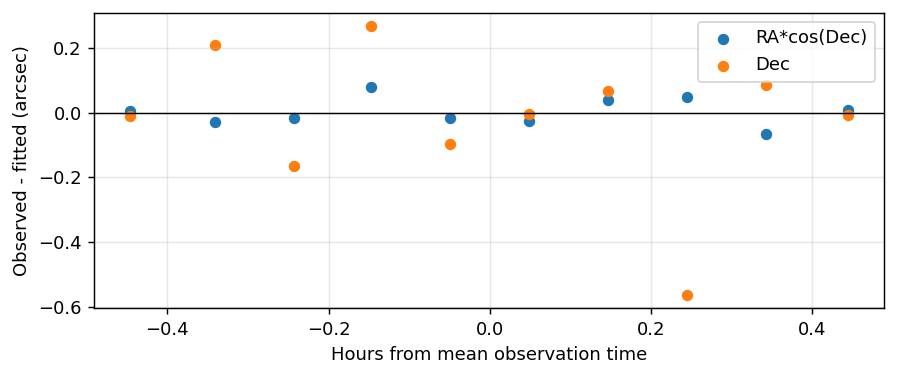

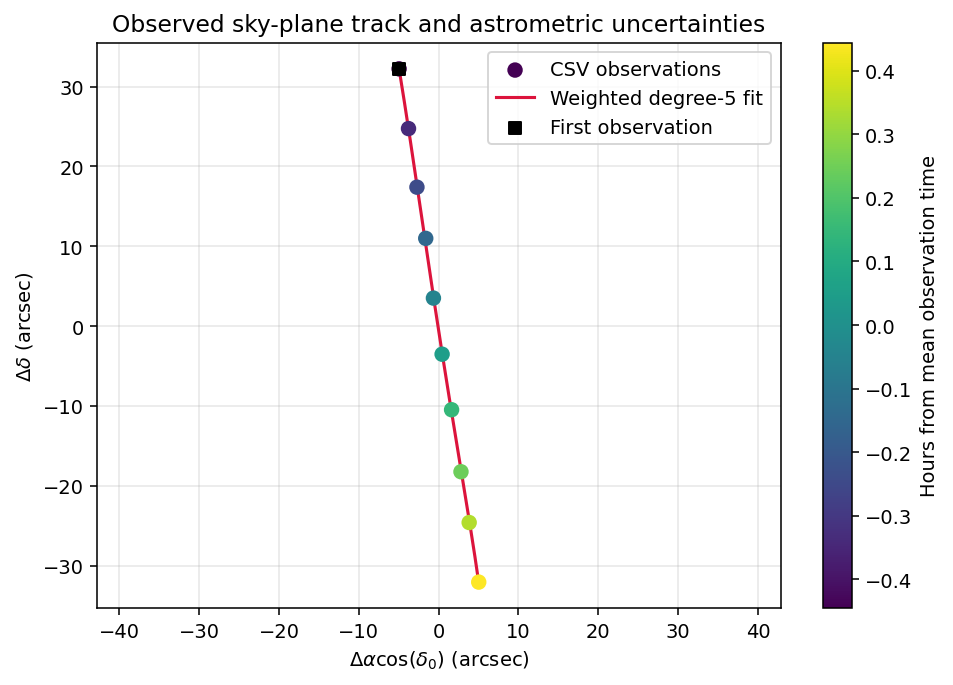

In [30]:
filename = Path("24445_20260929_radec.csv")
if not filename.exists():
    filename = Path("game12") / filename
if not filename.exists():
    raise FileNotFoundError(f"Observation CSV not found: {filename.resolve()}")

observations = pd.read_csv(filename)
required = {"JD", "RA", "DEC", "ERR_RA", "ERR_DEC"}
missing = required.difference(observations.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {sorted(missing)}")

jd = observations["JD"].to_numpy(dtype=float)
ra_deg = observations["RA"].to_numpy(dtype=float)
dec_deg = observations["DEC"].to_numpy(dtype=float)
err_ra_arcsec = observations["ERR_RA"].to_numpy(dtype=float)
err_dec_arcsec = observations["ERR_DEC"].to_numpy(dtype=float)
POLY_DEGREE = 5

fit = fit_observed_directions(jd, ra_deg, dec_deg, err_ra_arcsec, err_dec_arcsec, degree=POLY_DEGREE)
JD0 = fit["jd0"]
D, dotD, ddotD = fit["direction"], fit["direction_dot"], fit["direction_ddot"]

print(f"Observations: {len(observations)}; weighted polynomial degree: {POLY_DEGREE}")
print(f"Reference epoch JD(UTC): {JD0:.8f}")
print("Least-squares residual/error summary:")
display(fit["residual_summary"].set_index("quantity"))

fig, ax = plt.subplots(figsize=(7, 3), dpi=130)
ax.scatter((jd - JD0) * 24, fit["residual_ra_arcsec"], label="RA*cos(Dec)", s=28)
ax.scatter((jd - JD0) * 24, fit["residual_dec_arcsec"], label="Dec", s=28)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Hours from mean observation time")
ax.set_ylabel("Observed - fitted (arcsec)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Sky-plane positions relative to the mean observed direction; offsets and error bars are arcsec.
ra0_deg = float(np.mean(ra_deg))
dec0_deg = float(np.mean(dec_deg))
ra_offset = (ra_deg - ra0_deg) * np.cos(np.radians(dec0_deg)) * 3600.0
dec_offset = (dec_deg - dec0_deg) * 3600.0
time_hours = (jd - JD0) * 24.0

# Evaluate the fitted polynomial trajectory at a dense set of times for a smooth reference curve.
time_grid = np.linspace(jd.min(), jd.max(), 300)
x_grid = (time_grid - JD0) / fit["time_scale"]
design_grid = np.polynomial.polynomial.polyvander(x_grid, POLY_DEGREE)
ra_fit_deg = np.degrees(design_grid @ fit["ra_coeff"])
dec_fit_deg = np.degrees(design_grid @ fit["dec_coeff"])
ra_fit_offset = (ra_fit_deg - ra0_deg) * np.cos(np.radians(dec0_deg)) * 3600.0
dec_fit_offset = (dec_fit_deg - dec0_deg) * 3600.0

fig, ax = plt.subplots(figsize=(7, 5), dpi=140)
points = ax.scatter(ra_offset, dec_offset, c=time_hours, cmap="viridis", s=48, zorder=3,
                    label="CSV observations")
ax.errorbar(ra_offset, dec_offset, xerr=err_ra_arcsec, yerr=err_dec_arcsec,
            fmt="none", ecolor="0.35", alpha=0.65, capsize=2, zorder=2)
ax.plot(ra_fit_offset, dec_fit_offset, color="crimson", linewidth=1.6,
        label=f"Weighted degree-{POLY_DEGREE} fit")
ax.scatter(ra_offset[0], dec_offset[0], marker="s", color="black", s=38, label="First observation", zorder=4)
ax.set_xlabel(r"$\Delta\alpha\cos(\delta_0)$ (arcsec)")
ax.set_ylabel(r"$\Delta\delta$ (arcsec)")
ax.set_title("Observed sky-plane track and astrometric uncertainties")
ax.grid(True, alpha=0.3)
ax.set_aspect("equal", adjustable="datalim")
colorbar = fig.colorbar(points, ax=ax)
colorbar.set_label("Hours from mean observation time")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


In [32]:
g, dot_g, ddot_g = observer_heliocentric_state(JD0)

laplace_seed = None
try:
    laplace_seed = evaluate_laplace(fit)
    print("Laplace initial range solution:", f"r={laplace_seed[1]:.8f} AU, d={laplace_seed[2]:.8f} AU")
except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
    print("Laplace initial solution unavailable; starting direct orbit fit from a range/range-rate grid:", exc)

print("Observer state: Astropy builtin solar-system ephemeris; geocenter (no topocentric station offset).")
print("Orbit model: heliocentric two-body dynamics; light-time correction is not included.")

try:
    orbit_fit = fit_orbit_least_squares(
        jd, ra_deg, dec_deg, err_ra_arcsec, err_dec_arcsec, JD0, D, dotD,
        g, dot_g, laplace_seed=laplace_seed,
    )
    optimizer = orbit_fit["optimizer"]
    state_fit = orbit_fit["state"]
    r_fit_vec, dot_r_fit_vec = state_fit[:3], state_fit[3:]
    d_fit_vec = r_fit_vec - g
    d_fit = float(np.linalg.norm(d_fit_vec))
    dot_d_fit = float(d_fit_vec @ (dot_r_fit_vec - dot_g) / d_fit)
    elements_fit = orbital_elements(r_fit_vec, dot_r_fit_vec)
    element_errors = orbital_element_errors(state_fit, orbit_fit["covariance"])
    for name, value in elements_fit.items():
        if not np.isfinite(value):
            element_errors[name] = np.nan

    n_obs = len(jd)
    residual_ra_arcsec = orbit_fit["residuals"][:n_obs] * err_ra_arcsec
    residual_dec_arcsec = orbit_fit["residuals"][n_obs:] * err_dec_arcsec
    rms_ra = float(np.sqrt(np.mean(residual_ra_arcsec**2)))
    rms_dec = float(np.sqrt(np.mean(residual_dec_arcsec**2)))
    rms_2d = float(np.sqrt(np.mean(residual_ra_arcsec**2 + residual_dec_arcsec**2)))

    print("\nDirect orbit least-squares fit:")
    print(f"Optimizer converged: {optimizer.success} — {optimizer.message}")
    print(f"Weighted chi-square = {orbit_fit['chi2']:.6g}; dof = {orbit_fit['dof']}; "
          f"reduced chi-square = {orbit_fit['reduced_chi2']:.6g}")
    print(f"Residual RMS: RA*cos(Dec) = {rms_ra:.6f} arcsec; Dec = {rms_dec:.6f} arcsec; "
          f"2D = {rms_2d:.6f} arcsec")

    state_sigma = np.sqrt(np.maximum(0.0, np.diag(orbit_fit["covariance"])))
    state_table = pd.DataFrame({
        "estimate": state_fit,
        "formal 1-sigma": state_sigma,
        "unit": ["AU", "AU", "AU", "AU/day", "AU/day", "AU/day"],
    }, index=["x", "y", "z", "vx", "vy", "vz"])
    print("\nBest-fit heliocentric state at the mean observation epoch:")
    display(state_table)
    print(f"Geocentric distance d = {d_fit:.9f} AU; range rate dot(d) = {dot_d_fit:+.9f} AU/day")

    element_table = pd.DataFrame({
        "estimate": pd.Series(elements_fit),
        "formal 1-sigma": pd.Series(element_errors),
    })
    print("\nBest-fit orbital elements (J2000 ecliptic; local linearized formal errors):")
    display(element_table)

    if not optimizer.success:
        print("WARNING: The optimizer returned its best candidate but did not satisfy a convergence criterion.")
    if orbit_fit["reduced_chi2"] > 3:
        print("WARNING: The best-fit residuals are larger than expected from the stated measurement errors; "
              "treat the orbit and formal errors as poorly constrained.")
except (ValueError, RuntimeError, np.linalg.LinAlgError, FloatingPointError) as exc:
    print("DIRECT ORBIT FIT FAILED: no usable least-squares orbit could be determined.")
    print(f"Reason: {exc}")


Laplace initial solution unavailable; starting direct orbit fit from a range/range-rate grid: No positive physical Laplace range solution (d > d_min)
Observer state: Astropy builtin solar-system ephemeris; geocenter (no topocentric station offset).
Orbit model: heliocentric two-body dynamics; light-time correction is not included.

Direct orbit least-squares fit:
Optimizer converged: True — `xtol` termination condition is satisfied.
Weighted chi-square = 58.1799; dof = 14; reduced chi-square = 4.15571
Residual RMS: RA*cos(Dec) = 0.063328 arcsec; Dec = 0.226742 arcsec; 2D = 0.235420 arcsec

Best-fit heliocentric state at the mean observation epoch:


,estimate,formal 1-sigma,unit
x,1.086594,1.141507,AU
y,-0.083092,2.287847,AU
z,0.085481,0.537770,AU
vx,-0.005307,0.041246,AU/day
vy,0.022618,0.089761,AU/day
vz,0.003378,0.042528,AU/day


Geocentric distance d = 0.207565176 AU; range rate dot(d) = -0.008210351 AU/day

Best-fit orbital elements (J2000 ecliptic; local linearized formal errors):


,estimate,formal 1-sigma
a (AU),-30.342170,15079.976772
e,1.033113,16.461450
i (deg),14.663361,128.866980
Omega (deg),200.840347,57.182664
omega (deg),189.011404,10.614493
nu (deg),327.230706,90.520182
M (deg),NaN,NaN
P (day),NaN,NaN
